# Final paper analysis — revised

COCA analytic is excluded from paper results. Analytic true-model comparisons are kept only for Linear and NLI.

In [11]:
from pathlib import Path
import json
import math

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.stats import t as student_t

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 320)


def find_repo_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / "opinion_dynamics").exists():
            return candidate
    raise RuntimeError("Could not find repository root.")


REPO_ROOT = find_repo_root()
RESULTS_ROOT = REPO_ROOT / "opinion_dynamics" / "experiments" / "results"

SS_DIR = RESULTS_ROOT / "experiment_2026_09_30_final_unregularized_single_shot"
AB_DIR = RESULTS_ROOT / "experiment_2026_10_02_final_unregularized_abundant_matched_distribution"
BASELINE_DIR = RESULTS_ROOT / "experiment_2026_09_28_true_graph_static_and_analytic_baselines"

OUT_DIR = RESULTS_ROOT / "paper_analysis_2026_10_02_final_revised"
FIG_DIR = OUT_DIR / "figures"
TABLE_DIR = OUT_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

required = [
    SS_DIR / "COMPUTATION_COMPLETE.json",
    SS_DIR / "RUN_MANIFEST.json",
    SS_DIR / "combined_summary.csv",
    AB_DIR / "COMPUTATION_COMPLETE.json",
    AB_DIR / "combined_summary.csv",
    BASELINE_DIR / "COMPUTATION_COMPLETE.json",
    BASELINE_DIR / "true_graph_static_all_195.csv",
    BASELINE_DIR / "true_graph_analytic_supported_90.csv",
]
for path in required:
    if not path.exists():
        raise FileNotFoundError(path)

ss_complete = json.loads((SS_DIR / "COMPUTATION_COMPLETE.json").read_text(encoding="utf-8"))
ab_complete = json.loads((AB_DIR / "COMPUTATION_COMPLETE.json").read_text(encoding="utf-8"))
base_complete = json.loads((BASELINE_DIR / "COMPUTATION_COMPLETE.json").read_text(encoding="utf-8"))
ss_manifest = json.loads((SS_DIR / "RUN_MANIFEST.json").read_text(encoding="utf-8"))

assert ss_complete["status"] == "success"
assert ab_complete["status"] == "success"
assert base_complete["status"] == "success"
assert ss_complete["n_environments"] == 195
assert ss_complete["n_learned_runs"] == 585
assert ab_complete["n_environments"] == 195
assert ab_complete["n_learned_runs"] == 585
assert ss_manifest["scientific_config"]["regularization"] == "none"

print("Validated final unregularized runs.")

Validated final unregularized runs.


In [12]:
ss_raw = pd.read_csv(SS_DIR / "combined_summary.csv")
ab_raw = pd.read_csv(AB_DIR / "combined_summary.csv")
static_raw = pd.read_csv(BASELINE_DIR / "true_graph_static_all_195.csv")
analytic_raw_all = pd.read_csv(BASELINE_DIR / "true_graph_analytic_supported_90.csv")

# Paper decision: COCA analytic centrality is not used because the instantaneous
# Laplacian frequently has a non-unique zero eigenspace.
analytic_raw = analytic_raw_all[
    analytic_raw_all["dynamics"].isin(["laplacian", "nonlinearinfluence"])
].copy()

assert len(analytic_raw) == 65
assert set(analytic_raw["dynamics"]) == {"laplacian", "nonlinearinfluence"}
assert not analytic_raw["dynamics"].eq("coca").any()

SS_LEARNED = "learned_nonlinear"
AB_LEARNED = "learned_abundant_nonlinear"

RECOVERY_METRICS = [
    "A_MAE", "A_Fro", "row_TV", "true_edge_mass",
    "support_topdegree_recall", "edge_AP", "centrality_L1",
    "row_entropy_norm", "effective_neighbors",
]


def learned_env_table(df, policy, regime):
    x = df[df["policy"] == policy].copy()
    control_col = "final_mean" if regime == "single_shot" else "mean_end"
    prediction_col = (
        "final_fit_model_over_identity"
        if regime == "single_shot"
        else "model_over_identity"
    )

    needed = [
        "environment_id", "scenario_class", "family", "dynamics",
        "topology_seed", "opinion_seed", "environment_seed",
        control_col, prediction_col, *RECOVERY_METRICS,
    ]
    missing = [c for c in needed if c not in x.columns]
    if missing:
        raise RuntimeError(f"{regime} is missing columns: {missing}")

    agg = {
        control_col: "mean",
        prediction_col: "mean",
        **{m: "mean" for m in RECOVERY_METRICS},
        "scenario_class": "first",
        "family": "first",
        "dynamics": "first",
        "topology_seed": "first",
        "opinion_seed": "first",
        "environment_seed": "first",
    }
    out = x.groupby("environment_id", as_index=False).agg(agg)
    out = out.rename(columns={
        control_col: "control",
        prediction_col: "prediction_ratio",
    })
    out["regime"] = regime
    return out


ss_env = learned_env_table(ss_raw, SS_LEARNED, "single_shot")
ab_env = learned_env_table(ab_raw, AB_LEARNED, "abundant")

assert len(ss_env) == 195
assert len(ab_env) == 195

base_env = (
    ss_raw[ss_raw["policy"].isin(["no_control", "uniform", "true_graph"])]
    [["environment_id", "scenario_class", "family", "dynamics",
      "topology_seed", "opinion_seed", "environment_seed",
      "policy", "final_mean"]]
    .drop_duplicates()
    .pivot(
        index=[
            "environment_id", "scenario_class", "family", "dynamics",
            "topology_seed", "opinion_seed", "environment_seed",
        ],
        columns="policy",
        values="final_mean",
    )
    .reset_index()
)

control_env = (
    base_env
    .merge(
        ss_env[["environment_id", "control"]].rename(
            columns={"control": "learned_single_shot"}
        ),
        on="environment_id",
        validate="one_to_one",
    )
    .merge(
        ab_env[["environment_id", "control"]].rename(
            columns={"control": "learned_abundant"}
        ),
        on="environment_id",
        validate="one_to_one",
    )
)

control_env.to_csv(TABLE_DIR / "paper_control_environment_level.csv", index=False)
print("Loaded 195 final environments. COCA analytic excluded from paper data.")

Loaded 195 final environments. COCA analytic excluded from paper data.


In [13]:
def student_t_mean_ci(values, confidence=0.95):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]
    n = len(values)
    if n == 0:
        return np.nan, np.nan, np.nan
    mean = float(values.mean())
    if n == 1:
        return mean, np.nan, np.nan
    alpha = 1.0 - confidence
    critical = float(student_t.ppf(1.0 - alpha / 2.0, df=n - 1))
    half = critical * float(values.std(ddof=1)) / np.sqrt(n)
    return mean, mean - half, mean + half


def crossed_bootstrap_ci(group, value_col, n_boot=20_000, confidence=0.95, seed=20261002):
    pivot = group.pivot(index="topology_seed", columns="opinion_seed", values=value_col)
    if pivot.shape != (5, 5) or pivot.isna().any().any():
        raise ValueError(f"Expected complete 5x5 crossed design for {value_col}")

    matrix = pivot.to_numpy(dtype=float)
    rng = np.random.default_rng(seed)
    nr, nc = matrix.shape
    row_draws = rng.integers(0, nr, size=(n_boot, nr))
    col_draws = rng.integers(0, nc, size=(n_boot, nc))

    boot = np.empty(n_boot, dtype=float)
    for b in range(n_boot):
        boot[b] = matrix[np.ix_(row_draws[b], col_draws[b])].mean()

    alpha = 1.0 - confidence
    low, high = np.quantile(boot, [alpha / 2.0, 1.0 - alpha / 2.0])
    return float(matrix.mean()), float(low), float(high)


def mean_ci_for_group(group, value_col, seed=20261002):
    crossed = (
        len(group) == 25
        and group["scenario_class"].eq("unstructured_random").all()
        and group["topology_seed"].nunique() == 5
        and group["opinion_seed"].nunique() == 5
    )
    if crossed:
        return crossed_bootstrap_ci(group, value_col, seed=seed)
    return student_t_mean_ci(group[value_col].to_numpy(dtype=float))


MAIN_COLUMNS = {
    "No control": "no_control",
    "Uniform": "uniform",
    "Single-shot": "learned_single_shot",
    "Abundant": "learned_abundant",
    "True A": "true_graph",
}

group_rows = []
for (scenario_class, dynamics), g in control_env.groupby(
    ["scenario_class", "dynamics"], sort=False
):
    row = {
        "scenario_class": scenario_class,
        "dynamics": dynamics,
        "n_environments": len(g),
    }
    for label, col in MAIN_COLUMNS.items():
        row[label] = g[col].mean()
    row["single_shot_minus_uniform"] = (g["learned_single_shot"] - g["uniform"]).mean()
    row["abundant_minus_uniform"] = (g["learned_abundant"] - g["uniform"]).mean()
    row["single_shot_minus_true_A"] = (g["learned_single_shot"] - g["true_graph"]).mean()
    row["abundant_minus_true_A"] = (g["learned_abundant"] - g["true_graph"]).mean()
    group_rows.append(row)

control_summary = pd.DataFrame(group_rows)
control_summary.to_csv(TABLE_DIR / "paper_control_summary_by_dynamics.csv", index=False)

family_rows = []
for (scenario_class, dynamics, family), g in control_env.groupby(
    ["scenario_class", "dynamics", "family"], sort=False
):
    row = {
        "scenario_class": scenario_class,
        "dynamics": dynamics,
        "family": family,
        "n_environments": len(g),
    }
    for label, col in MAIN_COLUMNS.items():
        row[label] = g[col].mean()
    family_rows.append(row)

family_summary = pd.DataFrame(family_rows)
family_summary.to_csv(TABLE_DIR / "paper_control_summary_by_family.csv", index=False)

overall_rows = []
for regime, col in [
    ("single_shot", "learned_single_shot"),
    ("abundant", "learned_abundant"),
]:
    mean, low, high = student_t_mean_ci(control_env[col].to_numpy())
    overall_rows.append({
        "regime": regime,
        "n_environments": len(control_env),
        "learned_control": mean,
        "ci_low": low,
        "ci_high": high,
        "uniform": control_env["uniform"].mean(),
        "true_A": control_env["true_graph"].mean(),
        "learned_minus_uniform": (control_env[col] - control_env["uniform"]).mean(),
        "learned_minus_true_A": (control_env[col] - control_env["true_graph"]).mean(),
    })

overall_control = pd.DataFrame(overall_rows)
overall_control.to_csv(TABLE_DIR / "paper_control_overall.csv", index=False)

display(overall_control.round(6))
display(control_summary.round(6))

,regime,n_environments,learned_control,ci_low,ci_high,uniform,true_A,learned_minus_uniform,learned_minus_true_A
0,single_shot,195,0.763732,0.751585,0.775878,0.640688,0.784534,0.123044,-0.020803
1,abundant,195,0.756687,0.743134,0.770240,0.640688,0.784534,0.115999,-0.027847


,scenario_class,dynamics,n_environments,No control,Uniform,Single-shot,Abundant,True A,single_shot_minus_uniform,abundant_minus_uniform,single_shot_minus_true_A,abundant_minus_true_A
0,structured_mechanism,friedkinjohnsen,15,0.314785,0.417208,0.611277,0.607011,0.613842,0.194070,0.189803,-0.002564,-0.006831
1,structured_mechanism,hegselmannkrause,15,0.502782,0.669797,0.876433,0.624915,0.895423,0.206636,-0.044881,-0.018990,-0.270508
2,structured_mechanism,nonlinearinfluence,15,0.292275,0.527619,0.864993,0.860810,0.865575,0.337374,0.333191,-0.000582,-0.004766
3,unstructured_random,coca,25,0.548608,0.736536,0.763968,0.777333,0.781852,0.027432,0.040797,-0.017884,-0.004519
4,unstructured_random,friedkinjohnsen,25,0.540369,0.608784,0.684417,0.685874,0.695590,0.075632,0.077089,-0.011173,-0.009716
5,unstructured_random,hegselmannkrause,25,0.515436,0.685553,0.790234,0.833845,0.821060,0.104682,0.148292,-0.030825,0.012785
6,unstructured_random,laplacian,25,0.541025,0.693651,0.763632,0.813420,0.816446,0.069980,0.119769,-0.052815,-0.003026
7,unstructured_random,nonlinearinfluence,25,0.540243,0.693128,0.820113,0.834424,0.844726,0.126986,0.141296,-0.024613,-0.010302
8,unstructured_random,repulsion,25,0.520919,0.610938,0.723120,0.701620,0.734787,0.112181,0.090682,-0.011667,-0.033167


In [14]:
recovery = pd.concat([ss_env, ab_env], ignore_index=True)

recovery_rows = []
for (regime, scenario_class, dynamics), g in recovery.groupby(
    ["regime", "scenario_class", "dynamics"], sort=False
):
    row = {
        "regime": regime,
        "scenario_class": scenario_class,
        "dynamics": dynamics,
        "n_environments": len(g),
        "control": g["control"].mean(),
        "prediction_ratio": g["prediction_ratio"].mean(),
    }
    for metric in RECOVERY_METRICS:
        row[metric] = g[metric].mean()
    recovery_rows.append(row)

recovery_summary = pd.DataFrame(recovery_rows)
recovery_summary.to_csv(TABLE_DIR / "paper_A_recovery_by_dynamics.csv", index=False)

recovery_overall = (
    recovery.groupby("regime", as_index=False)
    .agg(
        n_environments=("environment_id", "size"),
        control=("control", "mean"),
        prediction_ratio=("prediction_ratio", "mean"),
        A_MAE=("A_MAE", "mean"),
        A_Fro=("A_Fro", "mean"),
        row_TV=("row_TV", "mean"),
        true_edge_mass=("true_edge_mass", "mean"),
        support_topdegree_recall=("support_topdegree_recall", "mean"),
        edge_AP=("edge_AP", "mean"),
        centrality_L1=("centrality_L1", "mean"),
        row_entropy_norm=("row_entropy_norm", "mean"),
        effective_neighbors=("effective_neighbors", "mean"),
    )
)
recovery_overall.to_csv(TABLE_DIR / "paper_A_recovery_overall.csv", index=False)

seed_rows = []
for regime, raw, policy, control_col in [
    ("single_shot", ss_raw, SS_LEARNED, "final_mean"),
    ("abundant", ab_raw, AB_LEARNED, "mean_end"),
]:
    x = raw[raw["policy"] == policy]
    for seed, g in x.groupby("learning_seed"):
        seed_rows.append({
            "regime": regime,
            "learning_seed": int(seed),
            "control": g[control_col].mean(),
            "row_TV": g["row_TV"].mean(),
            "true_edge_mass": g["true_edge_mass"].mean(),
            "edge_AP": g["edge_AP"].mean(),
            "centrality_L1": g["centrality_L1"].mean(),
        })

seed_summary = pd.DataFrame(seed_rows)
seed_summary.to_csv(TABLE_DIR / "paper_seed_robustness.csv", index=False)

display(recovery_overall.round(6))

,regime,n_environments,control,prediction_ratio,A_MAE,A_Fro,row_TV,true_edge_mass,support_topdegree_recall,edge_AP,centrality_L1,row_entropy_norm,effective_neighbors
0,abundant,195,0.756687,0.628675,0.077141,1.994300,0.578557,0.438096,0.719187,0.736025,0.487394,0.899318,10.913166
1,single_shot,195,0.763732,0.173999,0.050788,1.547163,0.380909,0.660697,0.697701,0.708441,0.497814,0.547512,5.107016


In [15]:
analytic_env = (
    analytic_raw[[
        "environment_id", "scenario_class", "family", "dynamics",
        "final_mean", "mean_over_campaigns",
        "max_laplacian_nullity",
        "fraction_campaigns_nonunique_centrality",
    ]]
    .rename(columns={
        "final_mean": "true_model",
        "mean_over_campaigns": "true_model_path",
    })
    .merge(
        static_raw[["environment_id", "final_mean", "mean_over_campaigns"]]
        .rename(columns={
            "final_mean": "true_A",
            "mean_over_campaigns": "true_A_path",
        }),
        on="environment_id",
        validate="one_to_one",
    )
    .merge(
        control_env[[
            "environment_id", "no_control", "uniform",
            "learned_single_shot", "learned_abundant",
            "topology_seed", "opinion_seed", "environment_seed",
        ]],
        on="environment_id",
        validate="one_to_one",
    )
)

assert len(analytic_env) == 65
assert not analytic_env["dynamics"].eq("coca").any()
assert analytic_env["max_laplacian_nullity"].max() == 1
assert np.allclose(
    analytic_env["fraction_campaigns_nonunique_centrality"].fillna(0.0),
    0.0,
)

analytic_rows = []
for (scenario_class, dynamics), g in analytic_env.groupby(
    ["scenario_class", "dynamics"], sort=False
):
    analytic_rows.append({
        "scenario_class": scenario_class,
        "dynamics": dynamics,
        "n_environments": len(g),
        "uniform": g["uniform"].mean(),
        "single_shot": g["learned_single_shot"].mean(),
        "abundant": g["learned_abundant"].mean(),
        "true_A": g["true_A"].mean(),
        "true_model": g["true_model"].mean(),
        "single_shot_minus_true_model": (
            g["learned_single_shot"] - g["true_model"]
        ).mean(),
        "abundant_minus_true_model": (
            g["learned_abundant"] - g["true_model"]
        ).mean(),
        "true_model_minus_true_A": (
            g["true_model"] - g["true_A"]
        ).mean(),
    })

analytic_summary = pd.DataFrame(analytic_rows)
analytic_env.to_csv(
    TABLE_DIR / "paper_true_model_environment_level_linear_nli.csv",
    index=False,
)
analytic_summary.to_csv(
    TABLE_DIR / "paper_true_model_summary_linear_nli.csv",
    index=False,
)

print("Paper true-model baselines: Linear and NLI only.")
display(analytic_summary.round(6))

Paper true-model baselines: Linear and NLI only.


,scenario_class,dynamics,n_environments,uniform,single_shot,abundant,true_A,true_model,single_shot_minus_true_model,abundant_minus_true_model,true_model_minus_true_A
0,unstructured_random,laplacian,25,0.693651,0.763632,0.813420,0.816446,0.816446,-0.052815,-0.003026,0.000000
1,unstructured_random,nonlinearinfluence,25,0.693128,0.820113,0.834424,0.844726,0.844771,-0.024657,-0.010346,0.000044
2,structured_mechanism,nonlinearinfluence,15,0.527619,0.864993,0.860810,0.865575,0.865575,-0.000582,-0.004766,0.000000


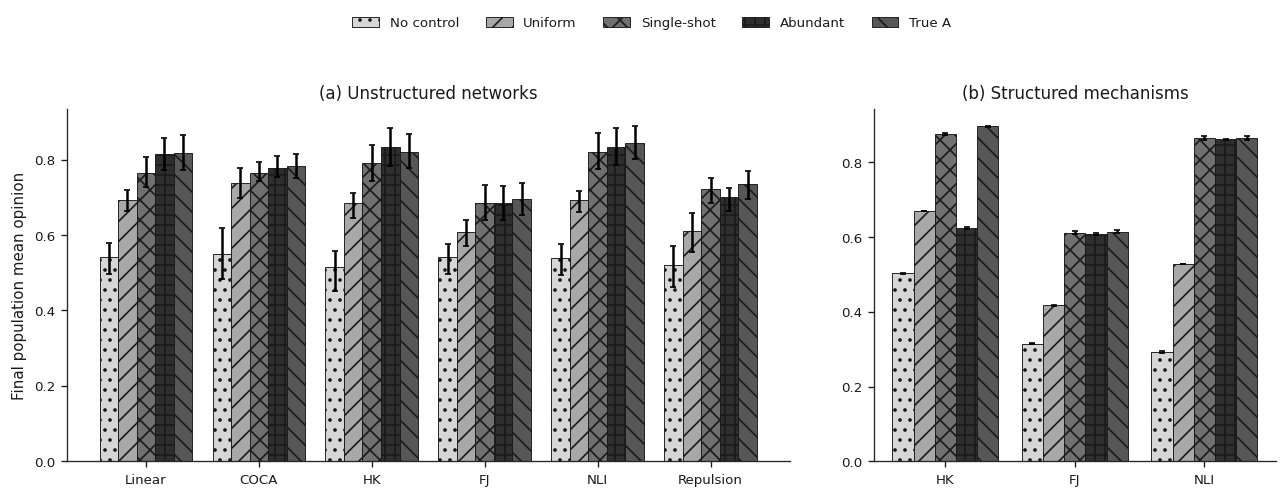

Saved: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_02_final_revised\figures\fig01_policy_overview_bw.pdf


In [16]:
PLOT_STYLE = "paper_bw"
SAVE_PNG = True
SAVE_PDF = True

mpl.rcdefaults()
mpl.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans", "Arial", "Liberation Sans"],
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "axes.edgecolor": "0.15",
    "text.color": "0.1",
    "axes.labelcolor": "0.1",
    "xtick.color": "0.1",
    "ytick.color": "0.1",
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
})

POLICY_STYLE = {
    "No control": {"color": "0.84", "hatch": ".."},
    "Uniform": {"color": "0.66", "hatch": "//"},
    "Single-shot": {"color": "0.44", "hatch": "xx"},
    "Abundant": {"color": "0.18", "hatch": "++"},
    "True A": {"color": "0.34", "hatch": "\\\\"},
    "True model": {"color": "0.06", "hatch": "oo"},
}

DYNAMICS_LABELS = {
    "laplacian": "Linear",
    "coca": "COCA",
    "hegselmannkrause": "HK",
    "friedkinjohnsen": "FJ",
    "nonlinearinfluence": "NLI",
    "repulsion": "Repulsion",
}
DYNAMICS_ORDER = [
    "laplacian", "coca", "hegselmannkrause",
    "friedkinjohnsen", "nonlinearinfluence", "repulsion",
]
STRUCTURED_ORDER = [
    "hegselmannkrause", "friedkinjohnsen", "nonlinearinfluence"
]
FAMILY_LABELS = {
    "ring_bridge": "Ring bridge",
    "paired_bridge": "Paired bridge",
    "dense_weak_bridge": "Dense weak bridge",
    "asymmetric_broadcast": "Asymmetric broadcast",
    "dual_broadcast": "Dual broadcast",
    "split_broadcast": "Split broadcast",
}

def save_figure(fig, stem):
    if SAVE_PNG:
        fig.savefig(FIG_DIR / f"{stem}.png")
    if SAVE_PDF:
        fig.savefig(FIG_DIR / f"{stem}.pdf")


def grouped_policy_bars(ax, data, categories, category_col, policy_columns, title):
    x = np.arange(len(categories))
    width = 0.82 / len(policy_columns)

    for p_index, (label, col) in enumerate(policy_columns.items()):
        means, lows, highs = [], [], []
        for c_index, category in enumerate(categories):
            g = data[data[category_col] == category]
            mean, low, high = mean_ci_for_group(
                g, col, seed=20261002 + 100 * p_index + c_index
            )
            means.append(mean)
            lows.append(low)
            highs.append(high)

        means = np.asarray(means)
        lows = np.asarray(lows)
        highs = np.asarray(highs)
        yerr = np.vstack([means - lows, highs - means])

        style = POLICY_STYLE[label]
        offset = (p_index - (len(policy_columns) - 1) / 2) * width
        ax.bar(
            x + offset,
            means,
            width=width,
            yerr=yerr,
            capsize=1.8,
            label=label,
            color=style["color"],
            edgecolor="0.1",
            linewidth=0.55,
            hatch=style["hatch"],
        )

    ax.set_xticks(x)
    if category_col == "dynamics":
        ax.set_xticklabels([DYNAMICS_LABELS[c] for c in categories])
    else:
        ax.set_xticklabels([FAMILY_LABELS.get(c, c) for c in categories])
    ax.set_title(title)


main_policy_columns = {
    "No control": "no_control",
    "Uniform": "uniform",
    "Single-shot": "learned_single_shot",
    "Abundant": "learned_abundant",
    "True A": "true_graph",
}

fig, axes = plt.subplots(
    1, 2,
    figsize=(13.0, 4.45),
    gridspec_kw={"width_ratios": [1.8, 1.0], "wspace": 0.15},
)

grouped_policy_bars(
    axes[0],
    control_env[control_env["scenario_class"] == "unstructured_random"],
    DYNAMICS_ORDER,
    "dynamics",
    main_policy_columns,
    "(a) Unstructured networks",
)
grouped_policy_bars(
    axes[1],
    control_env[control_env["scenario_class"] == "structured_mechanism"],
    STRUCTURED_ORDER,
    "dynamics",
    main_policy_columns,
    "(b) Structured mechanisms",
)

axes[0].set_ylabel("Final population mean opinion")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.015),
    frameon=False,
)
fig.subplots_adjust(top=0.82, bottom=0.16)
save_figure(fig, "fig01_policy_overview_bw")
plt.show()
plt.close(fig)

print("Saved:", FIG_DIR / "fig01_policy_overview_bw.pdf")

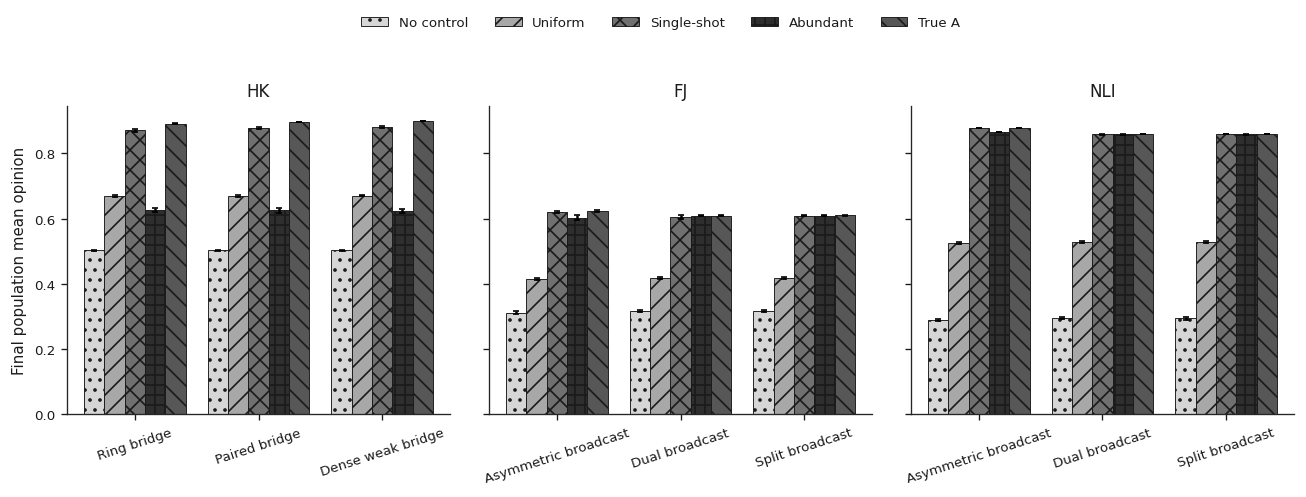

Saved: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_02_final_revised\figures\fig02_structured_families_bw.pdf


In [17]:
family_order = {
    "hegselmannkrause": ["ring_bridge", "paired_bridge", "dense_weak_bridge"],
    "friedkinjohnsen": ["asymmetric_broadcast", "dual_broadcast", "split_broadcast"],
    "nonlinearinfluence": ["asymmetric_broadcast", "dual_broadcast", "split_broadcast"],
}

structured = control_env[
    control_env["scenario_class"] == "structured_mechanism"
].copy()

fig, axes = plt.subplots(
    1, 3,
    figsize=(13.2, 4.35),
    sharey=True,
    gridspec_kw={"wspace": 0.10},
)

for ax, dynamics in zip(axes, STRUCTURED_ORDER):
    sub = structured[structured["dynamics"] == dynamics]
    grouped_policy_bars(
        ax,
        sub,
        family_order[dynamics],
        "family",
        main_policy_columns,
        DYNAMICS_LABELS[dynamics],
    )
    ax.tick_params(axis="x", rotation=18)

axes[0].set_ylabel("Final population mean opinion")
for ax in axes:
    if ax.get_legend() is not None:
        ax.get_legend().remove()

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.015),
    frameon=False,
)
fig.subplots_adjust(top=0.82, bottom=0.23)
save_figure(fig, "fig02_structured_families_bw")
plt.show()
plt.close(fig)

print("Saved:", FIG_DIR / "fig02_structured_families_bw.pdf")

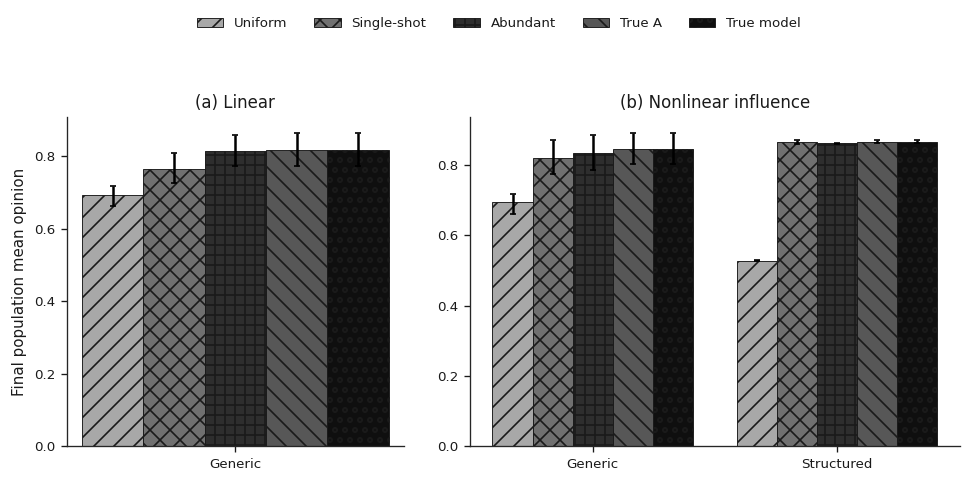

Saved: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_02_final_revised\figures\fig03_true_model_analytic_linear_nli_bw.pdf


In [18]:
analytic_policy_columns = {
    "Uniform": "uniform",
    "Single-shot": "learned_single_shot",
    "Abundant": "learned_abundant",
    "True A": "true_A",
    "True model": "true_model",
}


def analytic_panel(ax, groups, group_labels, dynamics, title):
    x = np.arange(len(groups))
    width = 0.82 / len(analytic_policy_columns)

    for p_index, (label, col) in enumerate(analytic_policy_columns.items()):
        means, lows, highs = [], [], []
        for g_index, scenario_class in enumerate(groups):
            g = analytic_env[
                (analytic_env["dynamics"] == dynamics)
                & (analytic_env["scenario_class"] == scenario_class)
            ].copy()
            if g.empty:
                means.append(np.nan)
                lows.append(np.nan)
                highs.append(np.nan)
                continue

            # Restore the design columns expected by mean_ci_for_group.
            if scenario_class == "unstructured_random":
                g["scenario_class"] = "unstructured_random"

            mean, low, high = mean_ci_for_group(
                g, col, seed=20261002 + 500 + 100 * p_index + g_index
            )
            means.append(mean)
            lows.append(low)
            highs.append(high)

        means = np.asarray(means, dtype=float)
        lows = np.asarray(lows, dtype=float)
        highs = np.asarray(highs, dtype=float)
        yerr = np.vstack([means - lows, highs - means])

        style = POLICY_STYLE[label]
        offset = (p_index - (len(analytic_policy_columns) - 1) / 2) * width
        ax.bar(
            x + offset,
            means,
            width=width,
            yerr=yerr,
            capsize=1.8,
            label=label,
            color=style["color"],
            edgecolor="0.1",
            linewidth=0.55,
            hatch=style["hatch"],
        )

    ax.set_xticks(x)
    ax.set_xticklabels(group_labels)
    ax.set_title(title)


fig, axes = plt.subplots(
    1, 2,
    figsize=(9.6, 4.35),
    gridspec_kw={"width_ratios": [1.0, 1.45], "wspace": 0.16},
)

analytic_panel(
    axes[0],
    ["unstructured_random"],
    ["Generic"],
    "laplacian",
    "(a) Linear",
)
analytic_panel(
    axes[1],
    ["unstructured_random", "structured_mechanism"],
    ["Generic", "Structured"],
    "nonlinearinfluence",
    "(b) Nonlinear influence",
)

axes[0].set_ylabel("Final population mean opinion")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.015),
    frameon=False,
)
fig.subplots_adjust(top=0.80, bottom=0.17)
save_figure(fig, "fig03_true_model_analytic_linear_nli_bw")
plt.show()
plt.close(fig)

print("Saved:", FIG_DIR / "fig03_true_model_analytic_linear_nli_bw.pdf")

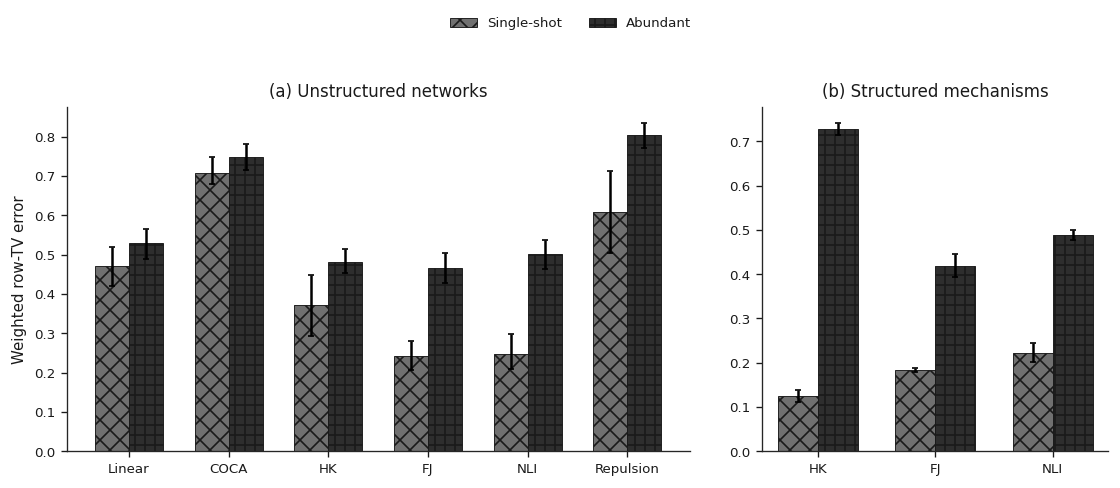

Saved: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_02_final_revised\figures\fig04_A_recovery_rowTV_bw.pdf


In [19]:
RECOVERY_STYLE = {
    "single_shot": {"label": "Single-shot", "color": "0.44", "hatch": "xx"},
    "abundant": {"label": "Abundant", "color": "0.18", "hatch": "++"},
}


def recovery_panel(ax, scenario_class, dynamics_order, title):
    x = np.arange(len(dynamics_order))
    width = 0.34

    for r_index, regime in enumerate(["single_shot", "abundant"]):
        source = ss_env if regime == "single_shot" else ab_env
        source = source[source["scenario_class"] == scenario_class]

        means, lows, highs = [], [], []
        for d_index, dynamics in enumerate(dynamics_order):
            g = source[source["dynamics"] == dynamics]
            mean, low, high = mean_ci_for_group(
                g, "row_TV", seed=20261002 + 800 + 100 * r_index + d_index
            )
            means.append(mean)
            lows.append(low)
            highs.append(high)

        means = np.asarray(means)
        lows = np.asarray(lows)
        highs = np.asarray(highs)
        yerr = np.vstack([means - lows, highs - means])

        style = RECOVERY_STYLE[regime]
        offset = (-0.5 if regime == "single_shot" else 0.5) * width
        ax.bar(
            x + offset,
            means,
            width=width,
            yerr=yerr,
            capsize=2,
            label=style["label"],
            color=style["color"],
            edgecolor="0.1",
            linewidth=0.55,
            hatch=style["hatch"],
        )

    ax.set_xticks(x)
    ax.set_xticklabels([DYNAMICS_LABELS[d] for d in dynamics_order])
    ax.set_title(title)


fig, axes = plt.subplots(
    1, 2,
    figsize=(11.2, 4.35),
    gridspec_kw={"width_ratios": [1.8, 1.0], "wspace": 0.15},
)
recovery_panel(
    axes[0],
    "unstructured_random",
    DYNAMICS_ORDER,
    "(a) Unstructured networks",
)
recovery_panel(
    axes[1],
    "structured_mechanism",
    STRUCTURED_ORDER,
    "(b) Structured mechanisms",
)

axes[0].set_ylabel("Weighted row-TV error")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    ncol=2,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.015),
    frameon=False,
)
fig.subplots_adjust(top=0.82, bottom=0.16)
save_figure(fig, "fig04_A_recovery_rowTV_bw")
plt.show()
plt.close(fig)

print("Saved:", FIG_DIR / "fig04_A_recovery_rowTV_bw.pdf")

In [20]:
def latex_table(df, path, columns=None, float_format="%.4f"):
    x = df if columns is None else df[columns]
    path.write_text(
        x.to_latex(index=False, float_format=float_format, na_rep="--"),
        encoding="utf-8",
    )


latex_table(
    overall_control,
    TABLE_DIR / "paper_control_overall.tex",
)
latex_table(
    recovery_overall,
    TABLE_DIR / "paper_A_recovery_overall.tex",
)
latex_table(
    analytic_summary,
    TABLE_DIR / "paper_true_model_linear_nli.tex",
)

headline = []
for _, r in overall_control.iterrows():
    headline.append(
        f"{r['regime']}: learned={r['learned_control']:.6f}, "
        f"uniform={r['uniform']:.6f}, true_A={r['true_A']:.6f}, "
        f"learned-uniform={r['learned_minus_uniform']:+.6f}, "
        f"learned-true_A={r['learned_minus_true_A']:+.6f}"
    )

for _, r in recovery_overall.iterrows():
    headline.append(
        f"{r['regime']} A recovery: row_TV={r['row_TV']:.6f}, "
        f"A_MAE={r['A_MAE']:.6f}, true_edge_mass={r['true_edge_mass']:.6f}, "
        f"edge_AP={r['edge_AP']:.6f}, centrality_L1={r['centrality_L1']:.6f}"
    )

headline.append(
    "Analytic true-model paper baseline restricted to Linear and NLI; COCA excluded."
)

(OUT_DIR / "paper_headline_numbers.txt").write_text(
    "\n".join(headline) + "\n",
    encoding="utf-8",
)

print("\n".join(headline))
print("\nFigures:", FIG_DIR)
print("Tables:", TABLE_DIR)
print("FINAL REVISED PAPER ANALYSIS COMPLETE")

single_shot: learned=0.763732, uniform=0.640688, true_A=0.784534, learned-uniform=+0.123044, learned-true_A=-0.020803
abundant: learned=0.756687, uniform=0.640688, true_A=0.784534, learned-uniform=+0.115999, learned-true_A=-0.027847
abundant A recovery: row_TV=0.578557, A_MAE=0.077141, true_edge_mass=0.438096, edge_AP=0.736025, centrality_L1=0.487394
single_shot A recovery: row_TV=0.380909, A_MAE=0.050788, true_edge_mass=0.660697, edge_AP=0.708441, centrality_L1=0.497814
Analytic true-model paper baseline restricted to Linear and NLI; COCA excluded.

Figures: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_02_final_revised\figures
Tables: d:\Work\repos\RL\unknown_graph_networks\opinion_dynamics\experiments\results\paper_analysis_2026_10_02_final_revised\tables
FINAL REVISED PAPER ANALYSIS COMPLETE
